# Iris Classification with a PyTorch Neural Network

This beginner-friendly project builds a multilayer perceptron (MLP) to classify three Iris flower species from four numerical measurements. The network uses a 4-16-8-3 architecture with ReLU activations and is trained with Adam and cross-entropy loss.

The notebook covers stratified training/validation/test splits (90/30/30 samples), feature standardization fitted only on training data, mini-batch training, selection of the best model by validation loss, learning curves, a classification report, a confusion matrix, and prediction from flower measurements.

The saved 100-epoch run achieved **90% test accuracy (27/30)**. This is a previously recorded result, not a new verification run; the small test set limits how broadly it can be interpreted.

**Requirements:** Python, PyTorch, NumPy, pandas, scikit-learn, Matplotlib, and Jupyter or Google Colab. Run the cells in order. The Iris dataset is included with scikit-learn. Step 7 explicitly selects the CPU, so the model runs on CPU even if a GPU was detected earlier.


# Step 1: Import libraries

In [ ]:
import copy
import random
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import(
    DataLoader,
    TensorDataset,
    random_split
)

from sklearn.datasets import load_iris
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import(
    classification_report,
    ConfusionMatrixDisplay
)





# Step 2: Set the random seed and select the device

A seed is a starting value for a pseudorandom number generator. Using the same seed makes it possible to reproduce the same sequence of random values.

42 is not special—you could use 10, 123, or another integer.

Sets PyTorch’s random seed. This affects operations such as initializing model weights and random sampling.

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("using devices:", device)

using devices: cpu


# Explanation:
- A seed makes random operations more repeatable.
- cuda means that PyTorch can use an available NVIDIA GPU.
- If no GPU is available, the notebook uses the CPU.
- Exact results can still differ across hardware and software versions.

# Step 3: Load and inspect the dataset

In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

iris_table = pd.DataFrame(
    X,
    columns = iris.feature_names
)

display(iris_table.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
iris_table['target'] = y
iris_table['speccies'] = iris.target_names[y]

display(iris_table.head(20))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,speccies
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa


In [ ]:
print("input shape:", X.shape)
print("Traget shape:", y.shape)
print("class names:", iris.target_names)

input shape: (150, 4)
Traget shape: (150,)
class names: ['setosa' 'versicolor' 'virginica']


| Feature | Meaning |
|---|---|
| Sepal length | Length of the flower’s sepal, in centimetres. |
| Sepal width | Width of the sepal. |
| Petal length | Length of the flower’s petal. |
| Petal width | Width of the petal. |

0 → setosa

1 → versicolor

2 → virginica

# Step 4: Create training, validation, and test sets

X_dev and y_dev temporarily hold the data that we will divide into training and validation sets.
| Variable | Contains |
|---|---|
| `X_development` | Flower measurements—the input features. |
| `y_development` | Corresponding flower species—the correct labels. |

In [ ]:
#Step 4: Create training, validation, and test sets

X_dev, X_test, y_dev, y_test = (
    train_test_split(
        X,
        y,
        test_size = 0.2,
        random_state = SEED,
        stratify = y
    )
)

# Use 25% of the remaining 80% for validation.
# This gives an overall split of 60% / 20% / 20%.
# Divide the development set into training and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size = 0.25,
    random_state = SEED,
    stratify = y_dev
)


print("Training Samples:", len(X_train))
print("Validation Sample:",  len(X_val))
print("Test samples:", len(X_test))


Training Samples: 90
Validation Sample: 30
Test samples: 30


# Step 5: Standardize the numerical features

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# scale validation data
X_val_scaled = scaler.transform(X_val)
# scale the testiing data
X_test_scaled = scaler.transform(X_test)


print("Original first training samples:")
print(X_train[0])

print("\n Standardized first training samples:")
print(X_train_scaled[0])

Original first training samples:
[6.7 3.3 5.7 2.1]

 Standardized first training samples:
[1.00233369 0.69246837 1.10593389 1.19177968]


Standardization transforms each feature using:

$$
z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}
$$

Here, $\mu_{\text{train}}$ is the mean and $\sigma_{\text{train}}$ is the standard deviation, both calculated from the training data.

For example, if a measurement is 6, its training mean is 5, and its training standard deviation is 0.5:

$$
z = \frac{6 - 5}{0.5} = 2
$$

**Why this matters:** Features with different scales can make neural-network optimization harder.

- `fit_transform()` learns the scaling statistics and applies them to training data.
- `transform()` applies those same statistics to validation and test data.
- Fitting the scaler on the full dataset would leak information from the held-out data.

# Step 6: Convert the data into tensors and batches

This function converts numerical features and their labels into PyTorch tensors, then pairs them into a dataset that a DataLoader can use.

A tensor is a numerical container used by PyTorch. Here, it is a two-dimensional table:
Four features

Flower 1 →     [5.1, 3.5, 1.4, 0.2]

Flower 2 →     [7.0, 3.2, 4.7, 1.4]

Flower 3 →     [6.3, 3.3, 6.0, 2.5]

In [ ]:
def make_tabular_datasets(features, labels):
  feature_tensor = torch.tensor(
      features,
      dtype=torch.float32
  )
  lable_tensor = torch.tensor(
      labels,
      dtype=torch.long
  )
  #Pair the inputs with their labels
  return TensorDataset(feature_tensor, lable_tensor)

iris_train_dataset = make_tabular_datasets(
    X_train_scaled, y_train
)
iris_val_dataset = make_tabular_datasets(
    X_val_scaled, y_val
)

iris_test_dataset = make_tabular_datasets(
    X_test_scaled, y_test
)

# load tensor data
iris_train_loader = DataLoader(
    iris_train_dataset,
    batch_size = 16,
    shuffle = True
)
iris_val_loader = DataLoader(
    iris_val_dataset,
    batch_size=16,
    shuffle=False
)

iris_test_loader = DataLoader(
    iris_test_dataset,
    batch_size=16,
    shuffle=False
)

features, labels = next(iter(iris_train_loader))

print("Batch input shape:", features.shape)
print("Batch label shape:", labels.shape)

#print("Features:")
#print(iris_train_dataset.tensors[0])

#print("\nLabels:")
#print(iris_train_dataset.tensors[1])

print(iris_train_dataset.tensors[0][:5])  # First five feature rows
print(iris_train_dataset.tensors[1][:5])  # Their corresponding labels


Batch input shape: torch.Size([16, 4])
Batch label shape: torch.Size([16])
tensor([[ 1.0023,  0.6925,  1.1059,  1.1918],
        [-0.9714,  1.1756, -1.3909, -1.1859],
        [ 0.7701, -0.5153,  0.4817,  0.3992],
        [-0.8553,  0.6925, -1.1639, -0.9217],
        [ 1.0023, -1.2400,  1.1627,  0.7955]])
tensor([2, 0, 1, 0, 2])


# Explanation:
- float32 stores numerical inputs as floating-point values.
- long stores class labels as integers.
- Each batch contains 16 flowers, with four measurements per flower.
- shuffle=True changes training order between epochs.
- Validation and test data do not need shuffling.

# Step 7: Build the MLP
We will use two small hidden layers:

| Layer | Dimensions | Purpose |
|---|---|---|
| Input | 4 features | Receives the flower measurements. |
| Hidden layer 1 | 4 → 16 | Learns combinations of the input measurements. |
| ReLU | 16 → 16 | Introduces nonlinearity. |
| Hidden layer 2 | 16 → 8 | Learns another representation. |
| ReLU | 8 → 8 | Introduces another nonlinear transformation. |
| Output | 8 → 3 | Produces one score per species. |

In [ ]:
class IrisMLP(nn.Module):
  def __init__(self):
    super().__init__()

    self.network = nn.Sequential(
        nn.Linear(4, 16),
        nn.ReLU(),

        nn.Linear(16, 8),
        nn.ReLU(),

        nn.Linear(8, 3)

    )

  def forward(self, x):
    return self.network(x)

torch.manual_seed(SEED)
device = torch.device("cpu")
mlp = IrisMLP().to(device)

print(mlp)

IrisMLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


# Step 8: Define one training/evaluation function

adds new gradients to existing gradients rather than replacing them. Therefore, we clear the old gradients before calculating new ones.
| Operation | Without clearing | With clearing |
|---|---:|---:|
| Batch 1 calculates a gradient | 0.3 | 0.3 |
| Batch 2 calculates a gradient of 0.2 | 0.3 + 0.2 = **0.5** | **0.2** |

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        # 1. Clear previous gradients.
        # clears the gradients from the previous batch so the next update uses only the current batch’s gradients.
        #A gradient tells the optimizer how changing a weight affects the loss.
        optimizer.zero_grad()

        # 2. Predict the classes.
        outputs = model(inputs)

        # 3. Calculate the prediction error.
        loss = criterion(outputs, targets)

        # 4. Calculate gradients.
        loss.backward()

        # 5. Update weights and biases.
        optimizer.step()

        # Record results for this batch. dim specifies the dimension along which PyTorch searches for the largest value.
        predictions = outputs.argmax(dim=1)
        batch_size = targets.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == targets).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

| Code | Meaning |
|---|---|
| `optimizer.zero_grad()` | Clear gradients from the previous batch. |
| `model(inputs)` | Perform the forward pass. |
| `criterion(outputs, targets)` | Calculate how wrong the predictions are. |
| `loss.backward()` | Calculate gradients through backpropagation. |
| `optimizer.step()` | Update the weights and biases. |

# 7.2. Evaluation function

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Predict and calculate error.
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            # Record results for this batch.
            predictions = outputs.argmax(dim=1)
            batch_size = targets.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == targets).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

Evaluation only measures performance. It does not calculate gradients or update model parameters.
- model.eval() sets the model to evaluation mode.
- torch.no_grad() disables gradient tracking.
- The same function works for validation and testing.

# Step 9: Define the complete training procedure

In [ ]:
def fit_model(
    model,
    train_loader,
    val_loader,
    epochs,
    learning_rate
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f} | "
                f"Train accuracy: {train_accuracy:.3f} | "
                f"Val accuracy: {val_accuracy:.3f}"
            )

    model.load_state_dict(best_state)

    print(
        f"\nRestored epoch {best_epoch}, "
        f"with validation loss {best_val_loss:.4f}"
    )

    return history

Explanation:
- An epoch is one complete pass through the training dataset.
- CrossEntropyLoss is appropriate for our multiclass classification tasks.
- Adam uses gradients to update weights and biases.
- The learning rate controls the update scale.
- Validation runs without parameter updates.
- state_dict() contains the model’s parameters and other saved state.
- We restore the checkpoint with the lowest validation loss.
Pass raw logits directly to CrossEntropyLoss; do not apply softmax first. This matches the documented PyTorch interface

# Step 10: Train the MLP

In [ ]:
mlp_history = fit_model(
    model=mlp,
    train_loader=iris_train_loader,
    val_loader=iris_val_loader,
    epochs=100,
    learning_rate=0.001
)

Epoch   1/100 | Train loss: 1.0913 | Val loss: 1.0831 | Train accuracy: 0.333 | Val accuracy: 0.333
Epoch  10/100 | Train loss: 0.9453 | Val loss: 0.9287 | Train accuracy: 0.656 | Val accuracy: 0.667
Epoch  20/100 | Train loss: 0.6804 | Val loss: 0.6495 | Train accuracy: 0.767 | Val accuracy: 0.833
Epoch  30/100 | Train loss: 0.4589 | Val loss: 0.4398 | Train accuracy: 0.867 | Val accuracy: 0.833
Epoch  40/100 | Train loss: 0.3424 | Val loss: 0.3444 | Train accuracy: 0.911 | Val accuracy: 0.867
Epoch  50/100 | Train loss: 0.2662 | Val loss: 0.2908 | Train accuracy: 0.933 | Val accuracy: 0.867
Epoch  60/100 | Train loss: 0.2104 | Val loss: 0.2570 | Train accuracy: 0.944 | Val accuracy: 0.867
Epoch  70/100 | Train loss: 0.1675 | Val loss: 0.2329 | Train accuracy: 0.956 | Val accuracy: 0.900
Epoch  80/100 | Train loss: 0.1346 | Val loss: 0.2178 | Train accuracy: 0.967 | Val accuracy: 0.900
Epoch  90/100 | Train loss: 0.1091 | Val loss: 0.2068 | Train accuracy: 0.967 | Val accuracy: 0.933


# Step 11: Plot the learning curves

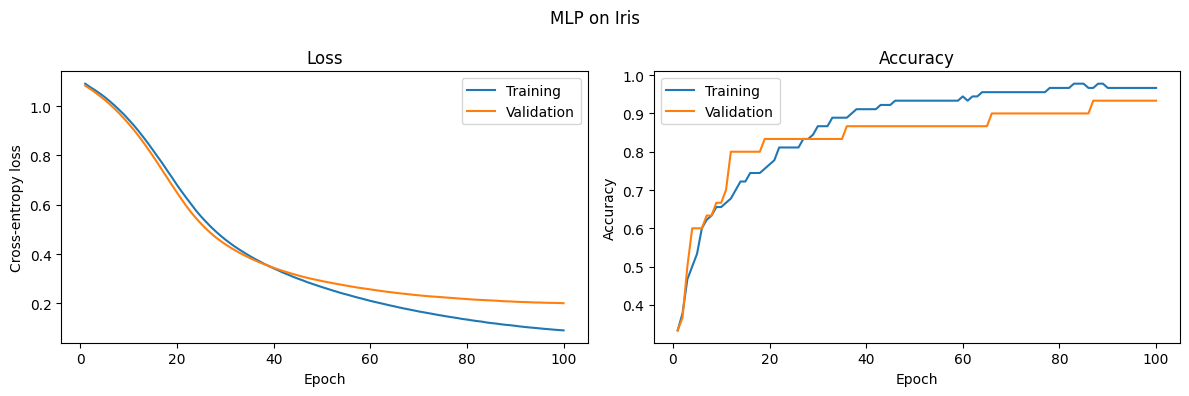

In [ ]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epochs, history["train_loss"], label="Training"
    )
    axes[0].plot(
        epochs, history["val_loss"], label="Validation"
    )
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()

    axes[1].plot(
        epochs, history["train_accuracy"], label="Training"
    )
    axes[1].plot(
        epochs, history["val_accuracy"], label="Validation"
    )
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(mlp_history, "MLP on Iris")

# Step 12: Evaluate on the test set

In [ ]:
def evaluate_classifier(model, loader, class_names):
    criterion = nn.CrossEntropyLoss()

    test_loss, test_accuracy = evaluate(
        model,
        loader,
        criterion
    )

    actual_labels = []
    predicted_labels = []

    model.eval()

    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)

            logits = model(inputs)
            predictions = logits.argmax(dim=1)

            actual_labels.extend(targets.cpu().tolist())
            predicted_labels.extend(predictions.cpu().tolist())

    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy:.2%}")

    class_ids = list(range(len(class_names)))

    print(
        classification_report(
            actual_labels,
            predicted_labels,
            labels=class_ids,
            target_names=list(class_names),
            digits=3,
            zero_division=0
        )
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        actual_labels,
        predicted_labels,
        labels=class_ids,
        display_labels=class_names,
        cmap="Blues",
        xticks_rotation=45,
        ax=ax
    )

    plt.tight_layout()
    plt.show()

    return test_accuracy

Test loss: 0.1848
Test accuracy: 90.00%
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.889     0.800     0.842        10
   virginica      0.818     0.900     0.857        10

    accuracy                          0.900        30
   macro avg      0.902     0.900     0.900        30
weighted avg      0.902     0.900     0.900        30



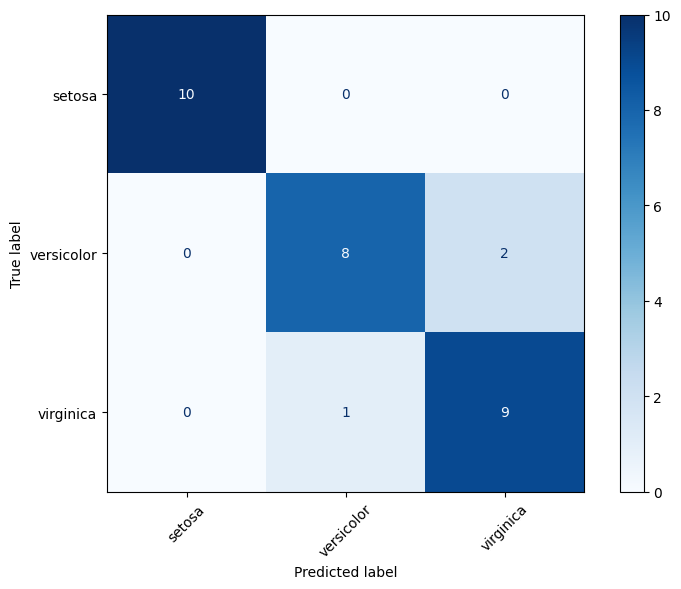

In [ ]:
mlp_test_accuracy = evaluate_classifier(
    mlp,
    iris_test_loader,
    iris.target_names
)

Explanation:
- Accuracy: The proportion of correctly classified samples.
- Precision: Among predictions for a class, how many are correct?
- Recall: Among actual members of a class, how many are identified?
- F1-score: The harmonic mean of precision and recall.
- Confusion matrix: Rows represent actual classes; columns represent predicted classes.
The Iris test set has only 30 samples. One additional mistake changes accuracy by approximately 3.33 percentage points, so small differences should not be overinterpreted.

# Step 13: Predict from new numerical measurements

In [ ]:
# Order:
# sepal length, sepal width, petal length, petal width
new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

new_flower_scaled = scaler.transform(new_flower)

new_flower_tensor = torch.tensor(
    new_flower_scaled,
    dtype=torch.float32
).to(device)

mlp.eval()

with torch.no_grad():
    logits = mlp(new_flower_tensor)
    probabilities = torch.softmax(logits, dim=1)
    predicted_class = probabilities.argmax(dim=1).item()

print("Predicted species:", iris.target_names[predicted_class])
#This loop pairs each flower species name with its predicted probability, so you can print them together.
#zip() combines items from two collections by their position.
for name, probability in zip(
    iris.target_names,
    probabilities[0].cpu().tolist()
):
    print(f"{name}: {probability:.3f}")

Predicted species: setosa
setosa: 0.998
versicolor: 0.002
virginica: 0.000
